In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install tensorflow

In [ ]:
!pip install tensorflow-keras

In [ ]:
from sklearn.preprocessing import RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from pathlib import Path
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import pickle
from typing import List, Optional, Dict, Tuple
import joblib
import os, re, ast, json, math, random, numpy as np, pandas as pd
import tensorflow as tf
import nibabel as nib
import seaborn as sns
import numpy as np
import tensorflow as tf
import keras
from tensorflow.keras import layers, models, regularizers, optimizers
from scipy.ndimage import zoom
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)

In [ ]:
CT_DIR  = Path("/content/drive/MyDrive/Colab Notebooks/ct")
RADIOMICS_DIR = Path("/content/drive/MyDrive/Colab Notebooks/radiomics_ct")

In [ ]:
MANIFEST_CSV = "/content/drive/MyDrive/Colab Notebooks/manifest.csv"
PATIENTS_CSV = "/content/drive/MyDrive/Colab Notebooks/PatientsData.csv"

USE_CROPPED_CT = True
CT_NIFTI_DIR = Path("/content/drive/MyDrive/Colab Notebooks/processed/ct_nifti")
CT_CROPPED_DIR = Path("/content/drive/MyDrive/Colab Notebooks/processed/ct_cropped_nifti")

USE_CROPPED_NPY = False
NPY_CROPPED_DIR = Path("/content/drive/MyDrive/Colab Notebooks/processed/npy_cropped")

TARGET_SHAPE = (128, 128, 128)
BATCH_SIZE = 2
EPOCHS = 25
LR = 1e-4
VAL_SPLIT = 0.2
TEST_SPLIT = 0.1
SEED = 42
AUTOTUNE = tf.data.AUTOTUNE

In [ ]:
MANIFEST_CSV = "/content/drive/MyDrive/Colab Notebooks/processed/manifest_preproc.csv"
LABELS_CSV = "/content/drive/MyDrive/Colab Notebooks/labels_TTF1_CK7.csv"
RADIOMICS_DIR = Path("/content/drive/MyDrive/Colab Notebooks/radiomics_ct")

PREFERRED_CT_SOURCE = "cropped_nifti"

def _norm_code(x: str) -> str:
    """Extrage doar cifrele din ID (ex: '2011 ' -> '2011')."""
    return pd.Series([x]).astype(str).str.extract(r"(\d+)")[0].iloc[0]

def _pick_ct_path(row, preferred=PREFERRED_CT_SOURCE):
    candidates_order = {
        "cropped_nifti": ["ct_cropped_nifti_path", "ct_nifti_path", "ct_cropped_npy_path", "ct_npy_path"],
        "cropped_npy": ["ct_cropped_npy_path", "ct_npy_path", "ct_cropped_nifti_path", "ct_nifti_path"],
        "nifti": ["ct_nifti_path", "ct_cropped_nifti_path", "ct_npy_path", "ct_cropped_npy_path"],
        "npy": ["ct_npy_path", "ct_cropped_npy_path", "ct_nifti_path", "ct_cropped_nifti_path"],
    }[preferred]

    chosen_col, chosen_path = None, None
    for col in candidates_order:
        if col in row and pd.notna(row[col]) and str(row[col]).strip():
            p = str(row[col]).strip()
            if os.path.exists(p):
                chosen_col, chosen_path = col, p
                break
    return chosen_col, chosen_path

def _build_radiomics_path(code: str) -> str:
    p = RADIOMICS_DIR / f"{code}_radiomics.txt"
    return str(p)

def _exists(p: str) -> bool:
    return (p is not None) and os.path.exists(p)


In [ ]:
def load_labels(labels_csv: str) -> pd.DataFrame:
    df = pd.read_csv(labels_csv, dtype=str)

    for col in ["TTF1", "CK7"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    df["Code"] = df["Code"].astype(str).apply(_norm_code)
    return df

def load_manifest(manifest_csv: str) -> pd.DataFrame:

    m = pd.read_csv(manifest_csv, dtype=str)
    m.columns = [c.strip() for c in m.columns]

    expected_cols = [
        "Code", "ct_nifti_path", "ct_npy_path",
        "ct_cropped_nifti_path", "ct_cropped_npy_path",
        "bbox_start_x", "bbox_start_y", "bbox_start_z",
        "bbox_size_x", "bbox_size_y", "bbox_size_z",
    ]

    if "Code" not in m.columns:
        alt = [c for c in m.columns if c.lower() == "code"]
        if alt:
            m.rename(columns={alt[0]: "Code"}, inplace=True)

    m["Code"] = m["Code"].astype(str).apply(_norm_code)
    return m

labels_df   = load_labels(LABELS_CSV)
manifest_df = load_manifest(MANIFEST_CSV)

print("Labels:", labels_df.shape, "| Manifest:", manifest_df.shape)

Labels: (87, 3) | Manifest: (87, 12)


In [ ]:
TARGET_SHAPE = (128, 128, 128)
BATCH_SIZE = 2
AUTOTUNE = tf.data.AUTOTUNE
INDEX_CSV = "/content/drive/MyDrive/Colab Notebooks/ck7_data_index_ct_radiomics.csv"

def load_index(index_csv: str) -> pd.DataFrame:
    df = pd.read_csv(index_csv)
    df["Code"] = df["Code"].astype(str)
    return df

data_index = load_index(INDEX_CSV)
display(data_index.head(5))


def load_ct_volume(ct_path: str, target_shape=TARGET_SHAPE):
    img = nib.load(ct_path)
    vol = img.get_fdata().astype(np.float32)
    vol = np.nan_to_num(vol)

    p1, p99 = np.percentile(vol, [1, 99])
    if p99 > p1:
        vol = np.clip((vol - p1) / (p99 - p1), 0, 1)
    else:
        vol = (vol - vol.min()) / (vol.max() - vol.min() + 1e-6)

    factors = (
        target_shape[0] / vol.shape[0],
        target_shape[1] / vol.shape[1],
        target_shape[2] / vol.shape[2]
    )
    vol_resized = zoom(vol, factors, order=1)

    vol_resized = vol_resized[..., np.newaxis]
    return vol_resized



def load_radiomics_features(path: str):
    feats = {}
    with open(path, "r") as f:
        for line in f:
            line = line.strip()
            if not line or ":" not in line:
                continue
            k, v = line.split(":", 1)
            k = k.strip()
            v = v.strip()
            try:
                v_clean = v.replace("np.float64(", "").replace(")", "")
                val = float(v_clean)
                if k.startswith("original_"):
                    feats[k] = val
            except Exception:
                continue
    return feats

,Code,TTF1,CK7,ct_path,ct_source_col,radiomics_path,ct_exists,radiomics_exists,ct_nifti_path,ct_npy_path,mask_nifti_path,ct_cropped_nifti_path,ct_cropped_npy_path,bbox_start_x,bbox_start_y,bbox_start_z,bbox_size_x,bbox_size_y,bbox_size_z
0,2011,1,0,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,116,155,192,237,180,61
1,3111,1,1,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,199,268,318,282,211,65
2,4111,1,0,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,49,166,138,357,206,78
3,5111,0,0,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,123,190,131,251,199,59
4,7011,0,0,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,189,186,226,220,208,56


In [ ]:
def build_radiomics_matrix(df: pd.DataFrame):
    rows = []
    for _, row in df.iterrows():
        feats = load_radiomics_features(row["radiomics_path"])
        feats["Code"] = row["Code"]
        rows.append(feats)
    r_df = pd.DataFrame(rows).fillna(0.0)
    return r_df


radiomics_df = build_radiomics_matrix(data_index)
display(radiomics_df.head(5))

,original_shape_Elongation,original_shape_Flatness,original_shape_LeastAxisLength,original_shape_MajorAxisLength,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_Maximum3DDiameter,original_shape_MeshVolume,original_shape_MinorAxisLength,...,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength,Code
0,0.779764,0.595793,152.530083,256.011877,276.193698,228.954491,233.925202,281.726390,2.565493e+06,199.628826,...,9.259426e-12,1.0,0.000003,2.058346e+09,0.0,1000000.0,0.0,0.0,0.0,2011
1,0.640112,0.586923,171.891225,292.868560,287.321700,244.669897,275.697298,287.813411,3.180012e+06,187.468622,...,5.710122e-12,1.0,0.000002,4.005624e+07,0.0,1000000.0,0.0,0.0,0.0,3111
2,0.755895,0.531086,171.433753,322.798641,382.922654,286.714140,338.740314,388.095296,5.550714e+06,244.001770,...,5.169792e-05,2.0,0.000003,3.971136e+11,0.0,1000000.0,0.0,0.0,0.0,4111
3,0.608135,0.578971,163.055600,281.630069,262.377589,212.843696,240.831892,274.271761,2.798453e+06,171.269007,...,7.403367e-12,1.0,0.000003,2.007464e+08,0.0,1000000.0,0.0,0.0,0.0,5111
4,0.732797,0.626018,154.585661,246.934857,233.918019,218.986848,228.973798,268.111990,2.421955e+06,180.953058,...,1.054923e-11,1.0,0.000003,2.358462e+09,0.0,1000000.0,0.0,0.0,0.0,7011


In [ ]:
merged = data_index.merge(radiomics_df, on="Code", how="left")
X_radio = merged[[c for c in merged.columns if c.startswith("original_")]].astype(np.float32).values

scaler = StandardScaler()
X_radio = scaler.fit_transform(X_radio).astype(np.float32)

y = merged[["TTF1", "CK7"]].astype(np.float32).values
ct_paths = merged["ct_path"].tolist()
codes = merged["Code"].tolist()

print("Patients number:", len(codes))
print("Vectors dimensions:", X_radio.shape[1])

Patients number: 87
Vectors dimensions: 107


In [ ]:
def generator(ct_paths, X_radio, y):
    for i in range(len(ct_paths)):
        vol = load_ct_volume(ct_paths[i])
        radio = X_radio[i]
        label = y[i]
        yield (vol, radio), label

output_signature = (
    (tf.TensorSpec(shape=TARGET_SHAPE+(1,), dtype=tf.float32),
     tf.TensorSpec(shape=(X_radio.shape[1],), dtype=tf.float32)),
    tf.TensorSpec(shape=(2,), dtype=tf.float32)
)

dataset = tf.data.Dataset.from_generator(
    lambda: generator(ct_paths, X_radio, y),
    output_signature=output_signature
)

dataset = dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)

for (vol, radio), label in dataset.take(1):
    print("Volum batch shape:", vol.shape)
    print("Radiomics batch shape:", radio.shape)
    print("Label batch shape:", label.shape)

Volum batch shape: (2, 128, 128, 128, 1)
Radiomics batch shape: (2, 107)
Label batch shape: (2, 2)


In [ ]:
TARGET_SHAPE = (128, 128, 128)
BATCH_SIZE = 2
EPOCHS = 25
LR = 1e-4
VAL_SPLIT = 0.2
TEST_SPLIT = 0.1
SEED = 42
AUTOTUNE = tf.data.AUTOTUNE
MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/effNet_TTF1_CK7_CT_radiomics_1.keras"
SCALER_PATH = "/content/drive/MyDrive/Colab Notebooks/radiomics_scaler_2.pkl"

In [ ]:
if 'scaler' in globals():
    with open(SCALER_PATH, "wb") as f:
        pickle.dump(scaler, f)
    print("Radiomics scaler saved at:", SCALER_PATH)

Radiomics scaler saved at: /content/drive/MyDrive/Colab Notebooks/radiomics_scaler_2.pkl


In [ ]:
def get_subset_by_ids(df, ids, ct_paths, X_radio, y):
    """Return the subset of samples (paths, radiomics, labels) for the given patient IDs."""
    df_ids = df[df["Code"].isin(ids)]
    idxs = df.index[df["Code"].isin(ids)].tolist()
    subset_ct_paths = [ct_paths[i] for i in idxs]
    subset_X_radio = X_radio[idxs]
    subset_y = y[idxs]
    return subset_ct_paths, subset_X_radio, subset_y

In [ ]:
def sample_generator(ct_paths, X_radio, y):
    for i in range(len(ct_paths)):
        vol = load_ct_volume(ct_paths[i])
        radio = X_radio[i].astype(np.float32)
        ttf1 = np.float32(y[i][0])
        ck7 = np.float32(y[i][1])
        yield (vol, radio), {"TTF1": ttf1, "CK7": ck7}

In [ ]:
def make_dataset(ct_paths, X_radio, y, batch_size, shuffle=False):
    output_signature = (
        (
            tf.TensorSpec(shape=TARGET_SHAPE+(1,), dtype=tf.float32),
            tf.TensorSpec(shape=(X_radio.shape[1],), dtype=tf.float32),
        ),
        {
            "TTF1": tf.TensorSpec(shape=(), dtype=tf.float32),
            "CK7": tf.TensorSpec(shape=(), dtype=tf.float32),
        }
    )

    ds = tf.data.Dataset.from_generator(
        lambda: sample_generator(ct_paths, X_radio, y),
        output_signature=output_signature
    )
    if shuffle:
        ds = ds.shuffle(buffer_size=min(256, len(ct_paths)))
    def expand_targets(inputs, targets):
        return inputs, {
            "TTF1": tf.expand_dims(targets["TTF1"], -1),
            "CK7": tf.expand_dims(targets["CK7"], -1)
        }
    ds = ds.map(expand_targets, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(AUTOTUNE)
    return ds

In [ ]:
def prepare_stratified_datasets(data_index, ct_paths, X_radio, y, val_split=0.15, test_split=0.15):
    df_temp = data_index.copy()
    df_temp['stratify_key'] = df_temp['TTF1'].astype(float).astype(str) + "_" + df_temp['CK7'].astype(float).astype(str)

    print(f"--- TOTAL PACIENTI DISPONIBILI: {len(df_temp)} ---")
    print(df_temp['stratify_key'].value_counts().sort_index())
    print("-" * 40)

    remainder_size = val_split + test_split

    try:
        train_df, remainder_df = train_test_split(
            df_temp,
            test_size=remainder_size,
            stratify=df_temp['stratify_key'],
            random_state=42
        )
    except ValueError as e:
        print(f"EROARE la Stratificare (prea putine date pentru o clasa): {e}")
        return None, None, None

    val_relative_size = val_split / remainder_size

    try:
        val_df, test_df = train_test_split(
            remainder_df,
            test_size=(1 - val_relative_size),
            stratify=remainder_df['stratify_key'],
            random_state=42
        )
    except ValueError as e:
        print(f"EROARE la split-ul Val/Test: {e}")
        return None, None, None

    print("\n=== RAPORT DISTRIBUTIE DUPA SPLIT ===")

    datasets = [("TRAIN", train_df), ("VALIDATION", val_df), ("TEST", test_df)]

    for name, df in datasets:
        print(f"\nSet: {name} (Total: {len(df)})")
        counts = df['stratify_key'].value_counts().sort_index()

        for key, count in counts.items():
            parts = key.split('_')
            ttf1_val = parts[0]
            ck7_val = parts[1]
            print(f"  -> TTF1: {ttf1_val} | CK7: {ck7_val} : {count} pacienti")

    print("\n=====================================\n")

    train_ids = train_df['Code'].values
    val_ids = val_df['Code'].values
    test_ids = test_df['Code'].values

    ct_train, radio_train, y_train = get_subset_by_ids(data_index, train_ids, ct_paths, X_radio, y)
    ct_val, radio_val, y_val = get_subset_by_ids(data_index, val_ids, ct_paths, X_radio, y)
    ct_test, radio_test, y_test = get_subset_by_ids(data_index, test_ids, ct_paths, X_radio, y)

    train_ds = make_dataset(ct_train, radio_train, y_train, BATCH_SIZE, shuffle=True)
    val_ds = make_dataset(ct_val, radio_val, y_val, BATCH_SIZE, shuffle=False)
    test_ds = make_dataset(ct_test, radio_test, y_test, BATCH_SIZE, shuffle=False)

    return train_ds, val_ds, test_ds

In [ ]:
train_ds, val_ds, test_ds = prepare_stratified_datasets(
    data_index,
    ct_paths,
    X_radio,
    y,
    val_split=0.10,
    test_split=0.10
)


--- TOTAL PACIENTI DISPONIBILI: 87 ---
stratify_key
0.0_0.0    14
0.0_1.0    12
1.0_0.0    31
1.0_1.0    30
Name: count, dtype: int64
----------------------------------------

=== RAPORT DISTRIBUTIE DUPA SPLIT ===

Set: TRAIN (Total: 69)
  -> TTF1: 0.0 | CK7: 0.0 : 11 pacienti
  -> TTF1: 0.0 | CK7: 1.0 : 9 pacienti
  -> TTF1: 1.0 | CK7: 0.0 : 25 pacienti
  -> TTF1: 1.0 | CK7: 1.0 : 24 pacienti

Set: VALIDATION (Total: 9)
  -> TTF1: 0.0 | CK7: 0.0 : 1 pacienti
  -> TTF1: 0.0 | CK7: 1.0 : 2 pacienti
  -> TTF1: 1.0 | CK7: 0.0 : 3 pacienti
  -> TTF1: 1.0 | CK7: 1.0 : 3 pacienti

Set: TEST (Total: 9)
  -> TTF1: 0.0 | CK7: 0.0 : 2 pacienti
  -> TTF1: 0.0 | CK7: 1.0 : 1 pacienti
  -> TTF1: 1.0 | CK7: 0.0 : 3 pacienti
  -> TTF1: 1.0 | CK7: 1.0 : 3 pacienti




In [ ]:
def conv3d_block(x, filters, k=3, s=1, p="same", l2_reg=1e-4):
    x = tf.keras.layers.Conv3D(
        filters,
        k,
        strides=s,
        padding=p,
        kernel_initializer="he_normal",
        kernel_regularizer=tf.keras.regularizers.l2(l2_reg),
    )(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    return x


def build_multimodal_twoheads_small(radio_dim, input_shape, lr, l2_reg=1e-4, dropout_rate=0.4):

    in_ct = tf.keras.Input(shape=input_shape, name="ct")

    x = conv3d_block(in_ct, 8, l2_reg=l2_reg)
    x = conv3d_block(x, 8, l2_reg=l2_reg)
    x = tf.keras.layers.MaxPool3D(2)(x)

    x = conv3d_block(x, 16, l2_reg=l2_reg)
    x = conv3d_block(x, 16, l2_reg=l2_reg)
    x = tf.keras.layers.MaxPool3D(2)(x)

    x = conv3d_block(x, 32, l2_reg=l2_reg)
    x = tf.keras.layers.MaxPool3D(2)(x)

    x = tf.keras.layers.GlobalAveragePooling3D()(x)
    x = tf.keras.layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(l2_reg),
    )(x)
    x = tf.keras.layers.Dropout(dropout_rate)(x)

    # ----- Radiomics branch (MLP mai mic + regularizare) -----
    in_radio = tf.keras.Input(shape=(radio_dim,), name="radio")

    r = tf.keras.layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(l2_reg),
    )(in_radio)
    r = tf.keras.layers.Dropout(dropout_rate)(r)

    r = tf.keras.layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(l2_reg),
    )(r)

    # ----- Fusion -----
    z = tf.keras.layers.Concatenate()([x, r])
    z = tf.keras.layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(l2_reg),
    )(z)
    z = tf.keras.layers.Dropout(dropout_rate)(z)

    # ----- Heads -----
    out_ttf1 = tf.keras.layers.Dense(
        1,
        activation="sigmoid",
        name="TTF1",
        kernel_regularizer=tf.keras.regularizers.l2(l2_reg),
    )(z)

    out_ck7 = tf.keras.layers.Dense(
        1,
        activation="sigmoid",
        name="CK7",
        kernel_regularizer=tf.keras.regularizers.l2(l2_reg),
    )(z)

    model = tf.keras.Model(
        inputs=[in_ct, in_radio],
        outputs={"TTF1": out_ttf1, "CK7": out_ck7},
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(lr),
        loss={"TTF1": "binary_crossentropy", "CK7": "binary_crossentropy"},
        metrics={
            "TTF1": [
                tf.keras.metrics.AUC(name="AUC"),
                tf.keras.metrics.BinaryAccuracy(name="BinAcc", threshold=0.5),
            ],
            "CK7": [
                tf.keras.metrics.AUC(name="AUC"),
                tf.keras.metrics.BinaryAccuracy(name="BinAcc", threshold=0.5),
            ],
        },
    )

    return model


In [ ]:
import numpy as np

def prepare_stratified_datasets(data_index, ct_paths, X_radio, y, val_split=0.15, test_split=0.15):
    """
    Split FIX (by patient IDs) in loc de stratified random split.
    Păstrează aceeași semnătură ca să poți apela la fel.
    """

    # --- ID-urile FIXE cerute ---
    FIXED_VAL_IDS = np.array(['13111', '3111', '19111', '56111', '2011', '50011', '65111', '24111'], dtype=str)
    FIXED_TEST_IDS = np.array(['25111', '45111', '42111', '89011', '33111', '36111', '55011', '80111', '48011'], dtype=str)

    df_temp = data_index.copy()

    # Ne asigurăm că 'Code' e string (ca să se potrivească exact cu ID-urile tale)
    df_temp["Code"] = df_temp["Code"].astype(str)

    # Stratify key doar pentru raportare (nu mai facem stratificare random)
    df_temp['stratify_key'] = (
        df_temp['TTF1'].astype(float).astype(int).astype(str) + "_" +
        df_temp['CK7'].astype(float).astype(int).astype(str)
    )

    print(f"--- TOTAL PACIENTI DISPONIBILI: {len(df_temp)} ---")
    print(df_temp['stratify_key'].value_counts().sort_index())
    print("-" * 40)

    # --- Validări ---
    all_ids = df_temp["Code"].values

    # IDs lipsă în data_index
    missing_val = FIXED_VAL_IDS[~np.isin(FIXED_VAL_IDS, all_ids)]
    missing_test = FIXED_TEST_IDS[~np.isin(FIXED_TEST_IDS, all_ids)]

    if len(missing_val) > 0:
        print("ATENTIE: urmatoarele ID-uri din VALIDATION nu exista in data_index:", missing_val)
    if len(missing_test) > 0:
        print("ATENTIE: urmatoarele ID-uri din TEST nu exista in data_index:", missing_test)

    # Duplicat între val și test
    overlap = np.intersect1d(FIXED_VAL_IDS, FIXED_TEST_IDS)
    if len(overlap) > 0:
        raise ValueError(f"ID-uri comune intre VALIDATION si TEST (nu e ok): {overlap}")

    # --- Măști ---
    mask_val = np.isin(all_ids, FIXED_VAL_IDS)
    mask_test = np.isin(all_ids, FIXED_TEST_IDS)
    mask_train = ~(mask_val | mask_test)

    train_df = df_temp[mask_train].copy()
    val_df = df_temp[mask_val].copy()
    test_df = df_temp[mask_test].copy()

    # --- Raport split ---
    print("\n=== RAPORT DISTRIBUTIE DUPA SPLIT (FIXED) ===")
    datasets = [("TRAIN", train_df), ("VALIDATION", val_df), ("TEST", test_df)]

    for name, df in datasets:
        print(f"\nSet: {name} (Total: {len(df)})")
        counts = df['stratify_key'].value_counts().sort_index()
        for key, count in counts.items():
            ttf1_val, ck7_val = key.split('_')
            print(f"  -> TTF1: {ttf1_val} | CK7: {ck7_val} : {count} pacienti")

    print("\n--------------------------------------------")
    print("Dataset Split Summary:")
    print(f"Train set: {len(train_df)} patients")
    print(f"Validation set: {len(val_df)} patients")
    print(f"Test set: {len(test_df)} patients")
    print("--------------------------------------------\n")

    print("Patients in VALIDATION set (IDs):")
    print(val_df["Code"].values)

    print("\nPatients in TEST set (IDs):")
    print(test_df["Code"].values)
    print("\n=====================================\n")

    # --- Extragem subset-urile cu funcția ta existentă ---
    train_ids = train_df['Code'].values
    val_ids = val_df['Code'].values
    test_ids = test_df['Code'].values

    ct_train, radio_train, y_train = get_subset_by_ids(data_index, train_ids, ct_paths, X_radio, y)
    ct_val, radio_val, y_val = get_subset_by_ids(data_index, val_ids, ct_paths, X_radio, y)
    ct_test, radio_test, y_test = get_subset_by_ids(data_index, test_ids, ct_paths, X_radio, y)

    # --- Dataset-uri TF ---
    train_ds = make_dataset(ct_train, radio_train, y_train, BATCH_SIZE, shuffle=True)
    val_ds = make_dataset(ct_val, radio_val, y_val, BATCH_SIZE, shuffle=False)
    test_ds = make_dataset(ct_test, radio_test, y_test, BATCH_SIZE, shuffle=False)

    return train_ds, val_ds, test_ds


In [ ]:
train_ds, val_ds, test_ds = prepare_stratified_datasets(
    data_index,
    ct_paths,
    X_radio,
    y,
    val_split=0.15,
    test_split=0.10
)


--- TOTAL PACIENTI DISPONIBILI: 87 ---
stratify_key
0_0    14
0_1    12
1_0    31
1_1    30
Name: count, dtype: int64
----------------------------------------

=== RAPORT DISTRIBUTIE DUPA SPLIT (FIXED) ===

Set: TRAIN (Total: 70)
  -> TTF1: 0 | CK7: 0 : 11 pacienti
  -> TTF1: 0 | CK7: 1 : 10 pacienti
  -> TTF1: 1 | CK7: 0 : 25 pacienti
  -> TTF1: 1 | CK7: 1 : 24 pacienti

Set: VALIDATION (Total: 8)
  -> TTF1: 0 | CK7: 0 : 1 pacienti
  -> TTF1: 0 | CK7: 1 : 1 pacienti
  -> TTF1: 1 | CK7: 0 : 3 pacienti
  -> TTF1: 1 | CK7: 1 : 3 pacienti

Set: TEST (Total: 9)
  -> TTF1: 0 | CK7: 0 : 2 pacienti
  -> TTF1: 0 | CK7: 1 : 1 pacienti
  -> TTF1: 1 | CK7: 0 : 3 pacienti
  -> TTF1: 1 | CK7: 1 : 3 pacienti

--------------------------------------------
Dataset Split Summary:
Train set: 70 patients
Validation set: 8 patients
Test set: 9 patients
--------------------------------------------

Patients in VALIDATION set (IDs):
['2011' '3111' '13111' '19111' '24111' '50011' '56111' '65111']

Patients in

In [ ]:
MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/model_TTF1_CK7_CT_radiomics_split_bogdan.keras"
EPOCHS = 25

radio_dim = X_radio.shape[1]
model = build_multimodal_twoheads_small(
    radio_dim=radio_dim,
    input_shape=TARGET_SHAPE + (1,),
    lr=LR,
    l2_reg=1e-4,
    dropout_rate=0.4,
)


model.summary()

callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_loss", save_best_only=True)
]

# Train
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

print("Evaluation on test set:")
test_metrics = model.evaluate(test_ds, return_dict=True)
print(test_metrics)

pred = model.predict(test_ds)
print("Sample predictions (first 5):")
print("TTF1:", pred["TTF1"][:5, 0])
print("CK7:", pred["CK7"][:5, 0])

print("Best model saved to:", MODEL_PATH)



Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ct (InputLayer)     │ (None, 128, 128,  │          0 │ -                 │
│                     │ 128, 1)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d (Conv3D)     │ (None, 128, 128,  │        224 │ ct[0][0]          │
│                     │ 128, 8)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │         32 │ conv3d[0][0]      │
│ (BatchNormalizatio… │ 128, 8)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 128, 8)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_1 (Conv3D)   │ (None, 128, 128,  │      1,736 │ activation[0][0]  │
│                     │ 128, 8)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │         32 │ conv3d_1[0][0]    │
│ (BatchNormalizatio… │ 128, 8)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 128, 8)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling3d       │ (None, 64, 64,    │          0 │ activation_1[0][… │
│ (MaxPooling3D)      │ 64, 8)            │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_2 (Conv3D)   │ (None, 64, 64,    │      3,472 │ max_pooling3d[0]… │
│                     │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │         64 │ conv3d_2[0][0]    │
│ (BatchNormalizatio… │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_3 (Conv3D)   │ (None, 64, 64,    │      6,928 │ activation_2[0][… │
│                     │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │         64 │ conv3d_3[0][0]    │
│ (BatchNormalizatio… │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling3d_1     │ (None, 32, 32,    │          0 │ activation_3[0][… │
│ (MaxPooling3D)      │ 32, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_4 (Conv3D)   │ (None, 32, 32,    │     13,856 │ max_pooling3d_1[… │
│                     │ 32, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv3d_4[0][0]  

 Total params: 59,114 (230.91 KB)

 Trainable params: 58,954 (230.29 KB)

 Non-trainable params: 160 (640.00 B)

Epoch 1/25
     35/Unknown 68s 204ms/step - CK7_AUC: 0.5418 - CK7_BinAcc: 0.4130 - CK7_loss: 0.7252 - TTF1_AUC: 0.5048 - TTF1_BinAcc: 0.6632 - TTF1_loss: 0.5792 - loss: 1.3540

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


35/35 ━━━━━━━━━━━━━━━━━━━━ 72s 322ms/step - CK7_AUC: 0.5406 - CK7_BinAcc: 0.4142 - CK7_loss: 0.7257 - TTF1_AUC: 0.5016 - TTF1_BinAcc: 0.6626 - TTF1_loss: 0.5820 - loss: 1.3572 - val_CK7_AUC: 0.6250 - val_CK7_BinAcc: 0.5000 - val_CK7_loss: 0.6884 - val_TTF1_AUC: 0.2917 - val_TTF1_BinAcc: 0.7500 - val_TTF1_loss: 0.6398 - val_loss: 1.3774 - learning_rate: 1.0000e-04
Epoch 2/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 33s 278ms/step - CK7_AUC: 0.3923 - CK7_BinAcc: 0.3754 - CK7_loss: 0.8057 - TTF1_AUC: 0.6201 - TTF1_BinAcc: 0.7863 - TTF1_loss: 0.5724 - loss: 1.4271 - val_CK7_AUC: 0.5625 - val_CK7_BinAcc: 0.5000 - val_CK7_loss: 0.6928 - val_TTF1_AUC: 0.5000 - val_TTF1_BinAcc: 0.7500 - val_TTF1_loss: 0.6310 - val_loss: 1.3724 - learning_rate: 1.0000e-04
Epoch 3/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 33s 279ms/step - CK7_AUC: 0.4675 - CK7_BinAcc: 0.4511 - CK7_loss: 0.7504 - TTF1_AUC: 0.5875 - TTF1_BinAcc: 0.7397 - TTF1_loss: 0.5763 - loss: 1.3753 - val_CK7_AUC: 0.5000 - val_CK7_BinAcc: 0.5000 - val_CK7_loss: 0.6932 

Loaded model from: /content/drive/MyDrive/Colab Notebooks/model_TTF1_CK7_CT_radiomics_split_bogdan.keras


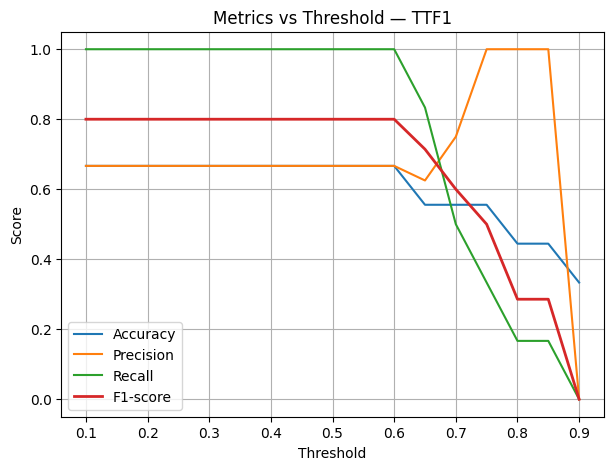

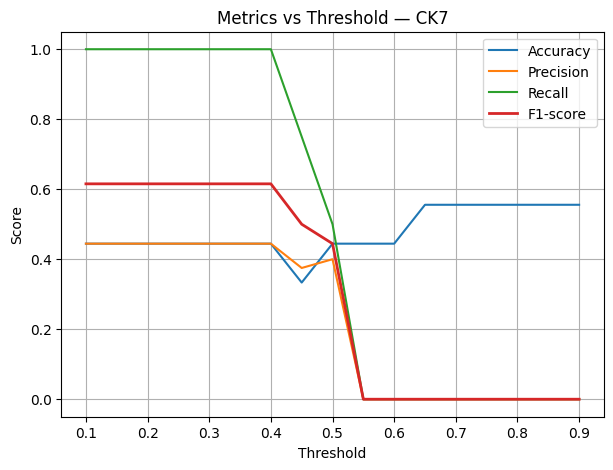

In [ ]:

MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/model_TTF1_CK7_CT_radiomics_split_bogdan.keras"
model = tf.keras.models.load_model(MODEL_PATH)
print("Loaded model from:", MODEL_PATH)

y_true_ttf1, y_true_ck7 = [], []
for _, targets in test_ds.unbatch().map(lambda x, t: (0, t)):
    y_true_ttf1.append(float(targets["TTF1"].numpy()[0]))
    y_true_ck7.append(float(targets["CK7"].numpy()[0]))
y_true_ttf1 = np.array(y_true_ttf1, dtype=int)
y_true_ck7 = np.array(y_true_ck7, dtype=int)

pred = model.predict(test_ds, verbose=0)
p_test_ttf1 = pred["TTF1"].ravel()
p_test_ck7 = pred["CK7"].ravel()

def plot_threshold_metrics(y_true, y_prob, name):
    thresholds = np.arange(0.10, 0.91, 0.05)
    acc, prec, rec, f1 = [], [], [], []
    for t in thresholds:
        y_pred = (y_prob >= t).astype(int)
        acc.append(accuracy_score(y_true, y_pred))
        prec.append(precision_score(y_true, y_pred, zero_division=0))
        rec.append(recall_score(y_true, y_pred, zero_division=0))
        f1.append(f1_score(y_true, y_pred, zero_division=0))

    plt.figure(figsize=(7,5))
    plt.plot(thresholds, acc,  label="Accuracy")
    plt.plot(thresholds, prec, label="Precision")
    plt.plot(thresholds, rec,  label="Recall")
    plt.plot(thresholds, f1,   label="F1-score", linewidth=2)
    plt.xlabel("Threshold")
    plt.ylabel("Score")
    plt.title(f"Metrics vs Threshold — {name}")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_threshold_metrics(y_true_ttf1,   p_test_ttf1,   "TTF1")
plot_threshold_metrics(y_true_ck7, p_test_ck7, "CK7")


AUC TTF1: 0.6666666666666667
AUC CK7 : 0.35


/tmp/ipython-input-656551796.py:11: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  y_true_ttf1.append(float(targets["TTF1"].numpy()))
/tmp/ipython-input-656551796.py:12: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  y_true_ck7.append(float(targets["CK7"].numpy()))


5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 948ms/step

TTF1 — binary metrics
Accuracy:  0.5556
Precision: 0.6250
Recall:    0.8333
F1-score:  0.7143
Confusion matrix [[TN FP] [FN TP]]:
[[0 3]
 [1 5]]


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


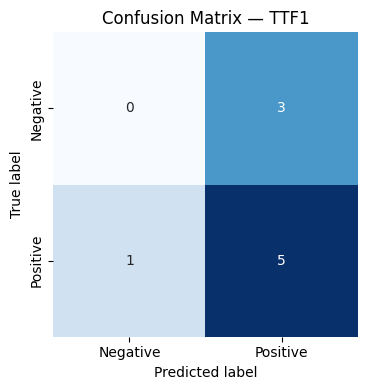


CK7 — binary metrics
Accuracy:  0.3333
Precision: 0.3750
Recall:    0.7500
F1-score:  0.5000
Confusion matrix [[TN FP] [FN TP]]:
[[0 5]
 [1 3]]


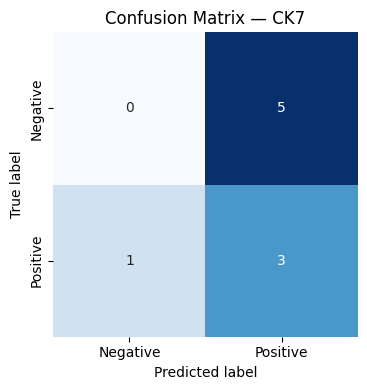

In [ ]:
from sklearn.metrics import roc_auc_score

auc_ttf1 = roc_auc_score(y_true_ttf1, p_test_ttf1)
auc_ck7  = roc_auc_score(y_true_ck7,  p_test_ck7)

print("AUC TTF1:", auc_ttf1)
print("AUC CK7 :", auc_ck7)

y_true_ttf1, y_true_ck7 = [], []
for (_, _), targets in test_ds.unbatch():
    y_true_ttf1.append(float(targets["TTF1"].numpy()))
    y_true_ck7.append(float(targets["CK7"].numpy()))
y_true_ttf1 = np.array(y_true_ttf1, dtype=int)
y_true_ck7 = np.array(y_true_ck7, dtype=int)

pred = model.predict(test_ds)
y_pred_ttf1 = (pred["TTF1"].ravel()   >= 0.65).astype(int) # 67
y_pred_ck7 = (pred["CK7"].ravel() >= 0.45).astype(int) # 48

def plot_confusion_matrix(y_true, y_pred, name):
    cm = confusion_matrix(y_true, y_pred)
    labels = ["Negative", "Positive"]

    plt.figure(figsize=(4.5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels, square=True)
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

def print_binary_metrics(y_true, y_pred, name):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    cm = confusion_matrix(y_true, y_pred)

    print(f"\n{name} — binary metrics")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print("Confusion matrix [[TN FP] [FN TP]]:")
    print(cm)

    plot_confusion_matrix(y_true, y_pred, name)

print_binary_metrics(y_true_ttf1,   y_pred_ttf1,   "TTF1")
print_binary_metrics(y_true_ck7, y_pred_ck7, "CK7")

In [ ]:
MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/model_TTF1_CK7_CT_small_split_bogdan.keras"
EPOCHS = 25

radio_dim = X_radio.shape[1]
model = build_multimodal_twoheads_small(
    radio_dim=radio_dim,
    input_shape=TARGET_SHAPE + (1,),
    lr=LR,
    l2_reg=1e-4,
    dropout_rate=0.4,
)


model.summary()

callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_loss", save_best_only=True)
]

# Train
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

print("Evaluation on test set:")
test_metrics = model.evaluate(test_ds, return_dict=True)
print(test_metrics)

pred = model.predict(test_ds)
print("Sample predictions (first 5):")
print("TTF1:", pred["TTF1"][:5, 0])
print("CK7:", pred["CK7"][:5, 0])

print("Best model saved to:", MODEL_PATH)



In [ ]:
# EFFICIENT NET

In [ ]:
IMG_SIZE = 128

def build_multimodal_effnet_2p5d_twoheads(
    radio_dim,
    input_shape_3d,          # ex: (D, H, W, 1)
    lr=1e-4,
    l2_reg=1e-4,
    dropout_rate=0.5,
    unfreeze_last=20
):
    # ------------------ CT input (3D) ------------------
    in_ct = layers.Input(shape=input_shape_3d, name="ct")

    # Extract 3 orthogonal mid-slices and stack as RGB-like image
    def vol_to_effnet_image(vol):
        # vol: (B, D, H, W, 1)
        vol = vol[..., 0]  # (B, D, H, W)

        d = tf.shape(vol)[1]
        h = tf.shape(vol)[2]
        w = tf.shape(vol)[3]

        axial   = vol[:, d // 2, :, :]   # (B, H, W)
        coronal = vol[:, :, h // 2, :]   # (B, D, W)
        sagittal= vol[:, :, :, w // 2]   # (B, D, H)

        axial   = tf.expand_dims(axial, axis=-1)     # (B, H, W, 1)
        coronal = tf.expand_dims(coronal, axis=-1)   # (B, D, W, 1)
        sagittal= tf.expand_dims(sagittal, axis=-1)  # (B, D, H, 1)

        axial   = tf.image.resize(axial, (IMG_SIZE, IMG_SIZE))
        coronal = tf.image.resize(coronal, (IMG_SIZE, IMG_SIZE))
        sagittal= tf.image.resize(sagittal, (IMG_SIZE, IMG_SIZE))

        x = tf.concat([axial, coronal, sagittal], axis=-1)  # (B, 128, 128, 3)
        return x

    x = layers.Lambda(vol_to_effnet_image, name="ct_to_2p5d")(in_ct)

    # Augmentation (ușor, pentru N mic)
    aug = tf.keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.05),
    ], name="augmentation")

    x = aug(x)

    # EfficientNet preprocess: așteaptă valori ~[0..255] apoi normalizează intern
    x = layers.Rescaling(255.0, name="to_255")(x)
    x = layers.Lambda(tf.keras.applications.efficientnet.preprocess_input,
                      name="effnet_preprocess")(x)

    # Backbone EfficientNet
    base_model = tf.keras.applications.EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )

    base_model.trainable = True
    if unfreeze_last is not None and unfreeze_last > 0:
        for layer in base_model.layers[:-unfreeze_last]:
            layer.trainable = False

    x = base_model(x, training=False)  # training=False ajută la stabilitate pe BN când e mostly frozen

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(dropout_rate)(x)

    x = layers.Dense(
        64, activation="relu",
        kernel_regularizer=regularizers.l2(l2_reg)
    )(x)
    x = layers.Dropout(dropout_rate)(x)

    # ------------------ Radiomics branch ------------------
    in_radio = layers.Input(shape=(radio_dim,), name="radio")

    r = layers.Dense(
        128, activation="relu",
        kernel_regularizer=regularizers.l2(l2_reg)
    )(in_radio)
    r = layers.BatchNormalization()(r)
    r = layers.Dropout(dropout_rate)(r)

    r = layers.Dense(
        64, activation="relu",
        kernel_regularizer=regularizers.l2(l2_reg)
    )(r)

    # ------------------ Fusion + heads ------------------
    z = layers.Concatenate()([x, r])

    z = layers.Dense(
        64, activation="relu",
        kernel_regularizer=regularizers.l2(l2_reg)
    )(z)
    z = layers.BatchNormalization()(z)
    z = layers.Dropout(dropout_rate)(z)

    out_ttf1 = layers.Dense(1, activation="sigmoid", name="TTF1")(z)
    out_ck7  = layers.Dense(1, activation="sigmoid", name="CK7")(z)

    model = models.Model(
        inputs=[in_ct, in_radio],
        outputs={"TTF1": out_ttf1, "CK7": out_ck7},
        name="Multimodal_EffNet_2p5D"
    )

    model.compile(
        optimizer=optimizers.Adam(learning_rate=lr),
        loss={"TTF1": "binary_crossentropy", "CK7": "binary_crossentropy"},
        metrics={
            "TTF1": [tf.keras.metrics.AUC(name="AUC"), tf.keras.metrics.BinaryAccuracy(name="BinAcc", threshold=0.5)],
            "CK7":  [tf.keras.metrics.AUC(name="AUC"), tf.keras.metrics.BinaryAccuracy(name="BinAcc", threshold=0.5)],
        },
    )

    return model


In [ ]:
MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/model_TTF1_CK7_CT_radiomics_effNet.keras"
EPOCHS = 25

radio_dim = X_radio.shape[1]

model = build_multimodal_effnet_2p5d_twoheads(
    radio_dim=radio_dim,
    input_shape_3d=TARGET_SHAPE + (1,),
    lr=LR,
    l2_reg=1e-4,
    dropout_rate=0.5,
    unfreeze_last=20   # ultimele ~20 straturi EfficientNet trainable
)

model.summary()

callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=False  # salvează TOT modelul (.keras)
    )
]

# ---------------- Train ----------------
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

# ---------------- Evaluation ----------------
print("Evaluation on test set:")
test_metrics = model.evaluate(test_ds, return_dict=True)
print(test_metrics)

# ---------------- Predictions ----------------
pred = model.predict(test_ds)
print("Sample predictions (first 5):")
print("TTF1:", pred["TTF1"][:5, 0])
print("CK7:", pred["CK7"][:5, 0])

print("Best model saved to:", MODEL_PATH)


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "Multimodal_EffNet_2p5D"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ct (InputLayer)     │ (None, 128, 128,  │          0 │ -                 │
│                     │ 128, 1)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ct_to_2p5d (Lambda) │ (None, 128, 128,  │          0 │ ct[0][0]          │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ augmentation        │ (None, 128, 128,  │          0 │ ct_to_2p5d[0][0]  │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ to_255 (Rescaling)  │ (None, 128, 128,  │          0 │ augmentation[0][… │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ effnet_preprocess   │ (None, 128, 128,  │          0 │ to_255[0][0]      │
│ (Lambda)            │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 4, 4,      │  4,049,571 │ effnet_preproces… │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ efficientnetb0[0… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ radio (InputLayer)  │ (None, 107)       │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 1280)      │      5,120 │ global_average_p… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     13,824 │ radio[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 1280)      │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_1[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │     81,984 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │      8,256 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 128)       │          0 │ dropout_1[0][0],  │
│ (Concatenate)       │                   │            │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 64)        │      8,256 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_3[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 4,167,909 (15.90 MB)

 Trainable params: 1,466,354 (5.59 MB)

 Non-trainable params: 2,701,555 (10.31 MB)

Epoch 1/25
     33/Unknown 237s 33ms/step - CK7_AUC: 0.5876 - CK7_BinAcc: 0.5864 - CK7_loss: 0.7397 - TTF1_AUC: 0.4981 - TTF1_BinAcc: 0.5456 - TTF1_loss: 0.8417 - loss: 1.6222

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


33/33 ━━━━━━━━━━━━━━━━━━━━ 287s 2s/step - CK7_AUC: 0.5868 - CK7_BinAcc: 0.5841 - CK7_loss: 0.7414 - TTF1_AUC: 0.4966 - TTF1_BinAcc: 0.5427 - TTF1_loss: 0.8447 - loss: 1.6286 - val_CK7_AUC: 0.5119 - val_CK7_BinAcc: 0.6154 - val_CK7_loss: 0.6746 - val_TTF1_AUC: 0.2639 - val_TTF1_BinAcc: 0.4615 - val_TTF1_loss: 0.6361 - val_loss: 1.5255 - learning_rate: 1.0000e-04
Epoch 2/25
33/33 ━━━━━━━━━━━━━━━━━━━━ 27s 163ms/step - CK7_AUC: 0.5067 - CK7_BinAcc: 0.5115 - CK7_loss: 1.0032 - TTF1_AUC: 0.3901 - TTF1_BinAcc: 0.5105 - TTF1_loss: 0.9364 - loss: 1.9822 - val_CK7_AUC: 0.5000 - val_CK7_BinAcc: 0.4615 - val_CK7_loss: 0.7760 - val_TTF1_AUC: 0.1944 - val_TTF1_BinAcc: 0.3077 - val_TTF1_loss: 0.7761 - val_loss: 1.5924 - learning_rate: 1.0000e-04
Epoch 3/25
33/33 ━━━━━━━━━━━━━━━━━━━━ 27s 179ms/step - CK7_AUC: 0.2637 - CK7_BinAcc: 0.4140 - CK7_loss: 1.2853 - TTF1_AUC: 0.2880 - TTF1_BinAcc: 0.3442 - TTF1_loss: 1.0119 - loss: 2.3378 - val_CK7_AUC: 0.5714 - val_CK7_BinAcc: 0.4615 - val_CK7_loss: 0.6741 - 

In [ ]:
import tensorflow as tf

MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/model_TTF1_CK7_CT_radiomics_effNet.keras"

def vol_to_effnet_image(vol):
    vol = vol[..., 0]
    d = tf.shape(vol)[1]
    h = tf.shape(vol)[2]
    w = tf.shape(vol)[3]

    axial    = vol[:, d // 2, :, :]
    coronal  = vol[:, :, h // 2, :]
    sagittal = vol[:, :, :, w // 2]

    axial    = tf.image.resize(tf.expand_dims(axial, axis=-1), (128, 128))
    coronal  = tf.image.resize(tf.expand_dims(coronal, axis=-1), (128, 128))
    sagittal = tf.image.resize(tf.expand_dims(sagittal, axis=-1), (128, 128))

    return tf.concat([axial, coronal, sagittal], axis=-1)

# IMPORTANT: funcția exactă folosită de layer-ul Lambda din model
effnet_preprocess_input = tf.keras.applications.efficientnet.preprocess_input

model = tf.keras.models.load_model(
    MODEL_PATH,
    custom_objects={
        "vol_to_effnet_image": vol_to_effnet_image,
        "preprocess_input": effnet_preprocess_input,   # <-- asta îți lipsea
    },
    safe_mode=False  # uneori ajută cu Lambda deserializare (Keras 3)
)

print("Loaded model from:", MODEL_PATH)


Loaded model from: /content/drive/MyDrive/Colab Notebooks/model_TTF1_CK7_CT_radiomics_effNet.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


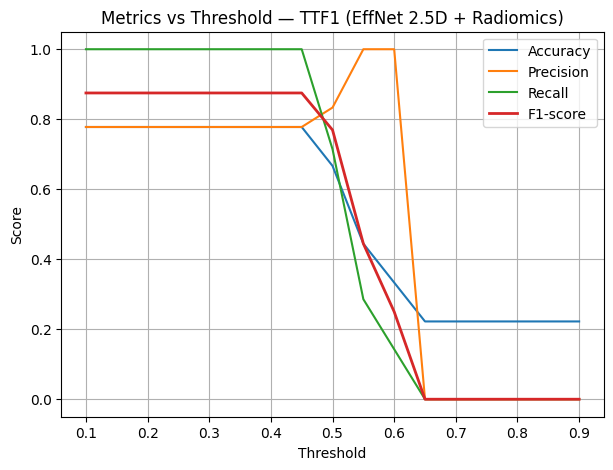

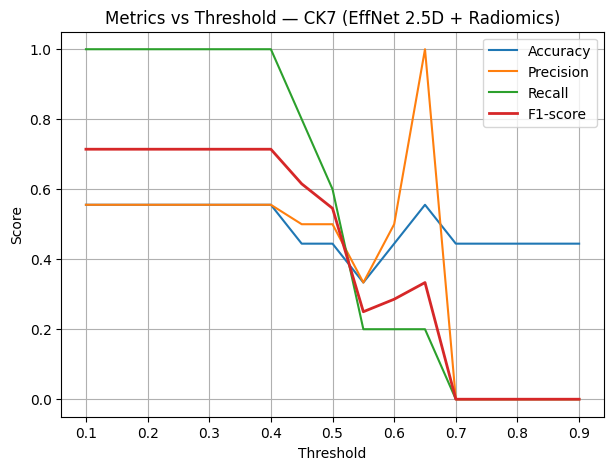

In [ ]:
# --------- y_true extraction (robust) ---------
y_true_ttf1, y_true_ck7 = [], []

for _, targets in test_ds.unbatch():
    y_true_ttf1.append(int(np.squeeze(targets["TTF1"].numpy())))
    y_true_ck7.append(int(np.squeeze(targets["CK7"].numpy())))

y_true_ttf1 = np.array(y_true_ttf1, dtype=int)
y_true_ck7  = np.array(y_true_ck7,  dtype=int)

# --------- predict ---------
pred = model.predict(test_ds, verbose=0)
p_test_ttf1 = pred["TTF1"].ravel()
p_test_ck7  = pred["CK7"].ravel()

def plot_threshold_metrics(y_true, y_prob, name):
    thresholds = np.arange(0.10, 0.91, 0.05)
    acc, prec, rec, f1 = [], [], [], []

    for t in thresholds:
        y_pred = (y_prob >= t).astype(int)
        acc.append(accuracy_score(y_true, y_pred))
        prec.append(precision_score(y_true, y_pred, zero_division=0))
        rec.append(recall_score(y_true, y_pred, zero_division=0))
        f1.append(f1_score(y_true, y_pred, zero_division=0))

    plt.figure(figsize=(7,5))
    plt.plot(thresholds, acc,  label="Accuracy")
    plt.plot(thresholds, prec, label="Precision")
    plt.plot(thresholds, rec,  label="Recall")
    plt.plot(thresholds, f1,   label="F1-score", linewidth=2)
    plt.xlabel("Threshold")
    plt.ylabel("Score")
    plt.title(f"Metrics vs Threshold — {name} (EffNet 2.5D + Radiomics)")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_threshold_metrics(y_true_ttf1, p_test_ttf1, "TTF1")
plot_threshold_metrics(y_true_ck7,  p_test_ck7,  "CK7")


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



TTF1 — binary metrics (EffNet 2.5D + Radiomics)
Threshold: 0.48
Accuracy:  0.7778
Precision: 0.8571
Recall:    0.8571
F1-score:  0.8571
Confusion matrix [[TN FP] [FN TP]]:
[[1 1]
 [1 6]]


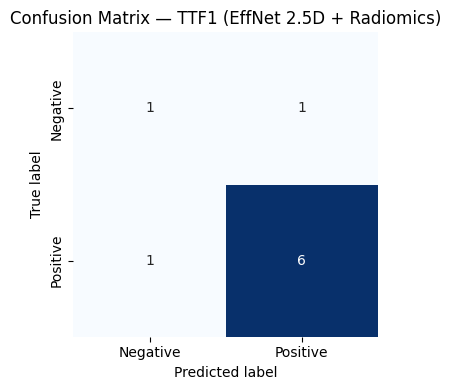


CK7 — binary metrics (EffNet 2.5D + Radiomics)
Threshold: 0.57
Accuracy:  0.3333
Precision: 0.3333
Recall:    0.2000
F1-score:  0.2500
Confusion matrix [[TN FP] [FN TP]]:
[[2 2]
 [4 1]]


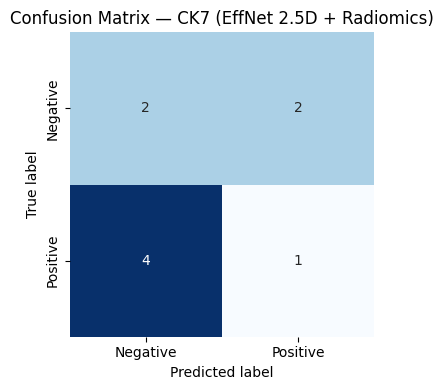

In [ ]:
# dacă vrei aceleași praguri ca înainte:
TTF1_THR = 0.48
CK7_THR  = 0.57

pred = model.predict(test_ds, verbose=0)

y_pred_ttf1 = (pred["TTF1"].ravel() >= TTF1_THR).astype(int)
y_pred_ck7  = (pred["CK7"].ravel()  >= CK7_THR).astype(int)

def plot_confusion_matrix(y_true, y_pred, name):
    cm = confusion_matrix(y_true, y_pred)
    labels = ["Negative", "Positive"]

    plt.figure(figsize=(4.5, 4))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=labels, yticklabels=labels, square=True
    )
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.title(f"Confusion Matrix — {name} (EffNet 2.5D + Radiomics)")
    plt.tight_layout()
    plt.show()

def print_binary_metrics(y_true, y_pred, name):
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec  = recall_score(y_true, y_pred, zero_division=0)
    f1   = f1_score(y_true, y_pred, zero_division=0)
    cm   = confusion_matrix(y_true, y_pred)

    print(f"\n{name} — binary metrics (EffNet 2.5D + Radiomics)")
    print(f"Threshold: {TTF1_THR if name=='TTF1' else CK7_THR:.2f}")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print("Confusion matrix [[TN FP] [FN TP]]:")
    print(cm)

    plot_confusion_matrix(y_true, y_pred, name)

print_binary_metrics(y_true_ttf1, y_pred_ttf1, "TTF1")
print_binary_metrics(y_true_ck7,  y_pred_ck7,  "CK7")


In [ ]:
!pip -q install efficientnet-3D


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers, optimizers

def conv3d_bn_swish(x, filters, k=3, s=1, l2_reg=1e-4, name=None):
    x = layers.Conv3D(
        filters, k, strides=s, padding="same", use_bias=False,
        kernel_initializer="he_normal",
        kernel_regularizer=regularizers.l2(l2_reg),
        name=None if name is None else name + "_conv"
    )(x)
    x = layers.BatchNormalization(name=None if name is None else name + "_bn")(x)
    x = layers.Activation("swish", name=None if name is None else name + "_swish")(x)
    return x

def se_block_3d(x, se_ratio=0.25, l2_reg=1e-4, name=None):
    ch = int(x.shape[-1])
    reduced = max(1, int(ch * se_ratio))

    se = layers.GlobalAveragePooling3D(name=None if name is None else name + "_gap")(x)
    se = layers.Dense(
        reduced, activation="swish",
        kernel_regularizer=regularizers.l2(l2_reg),
        name=None if name is None else name + "_fc1"
    )(se)
    se = layers.Dense(
        ch, activation="sigmoid",
        kernel_regularizer=regularizers.l2(l2_reg),
        name=None if name is None else name + "_fc2"
    )(se)
    se = layers.Reshape((1, 1, 1, ch), name=None if name is None else name + "_reshape")(se)
    return layers.Multiply(name=None if name is None else name + "_scale")([x, se])

def mbconv3d(
    x,
    out_filters,
    expand_ratio=4,
    k=3,
    s=1,
    se_ratio=0.25,
    drop_rate=0.0,
    l2_reg=1e-4,
    name="mb"
):
    in_filters = int(x.shape[-1])
    residual = x

    # Expand (1x1x1)
    hidden = int(in_filters * expand_ratio)
    if expand_ratio != 1:
        x = conv3d_bn_swish(x, hidden, k=1, s=1, l2_reg=l2_reg, name=name + "_expand")
    else:
        hidden = in_filters

    # "Depthwise-like" 3D conv (we use standard Conv3D for max compatibility)
    x = conv3d_bn_swish(x, hidden, k=k, s=s, l2_reg=l2_reg, name=name + "_conv3d")

    # SE
    if se_ratio and se_ratio > 0:
        x = se_block_3d(x, se_ratio=se_ratio, l2_reg=l2_reg, name=name + "_se")

    # Project (1x1x1) no activation
    x = layers.Conv3D(
        out_filters, 1, padding="same", use_bias=False,
        kernel_regularizer=regularizers.l2(l2_reg),
        name=name + "_project_conv"
    )(x)
    x = layers.BatchNormalization(name=name + "_project_bn")(x)

    # Skip (only if same shape)
    if s == 1 and in_filters == out_filters:
        if drop_rate and drop_rate > 0:
            x = layers.Dropout(drop_rate, name=name + "_drop")(x)
        x = layers.Add(name=name + "_add")([x, residual])

    return x

def build_effnetlike3d_multimodal_twoheads(
    radio_dim,
    input_shape_3d,     # TARGET_SHAPE + (1,)
    lr=1e-4,
    l2_reg=3e-5,
    drop_img=0.35,
    drop_radio=0.35,
    drop_fusion=0.35,
    use_focal=True
):
    in_ct = layers.Input(shape=input_shape_3d, name="ct")

    # Stem (downsample a bit for memory + generalization)
    x = conv3d_bn_swish(in_ct, 16, k=3, s=2, l2_reg=l2_reg, name="stem")  # /2

    # Blocks (small, for N~87)
    x = mbconv3d(x, 16, expand_ratio=2, k=3, s=1, se_ratio=0.25, drop_rate=0.0, l2_reg=l2_reg, name="b1")
    x = mbconv3d(x, 24, expand_ratio=3, k=3, s=2, se_ratio=0.25, drop_rate=0.0, l2_reg=l2_reg, name="b2")  # /4
    x = mbconv3d(x, 24, expand_ratio=3, k=3, s=1, se_ratio=0.25, drop_rate=0.0, l2_reg=l2_reg, name="b3")
    x = mbconv3d(x, 32, expand_ratio=4, k=3, s=2, se_ratio=0.25, drop_rate=0.0, l2_reg=l2_reg, name="b4")  # /8
    x = mbconv3d(x, 32, expand_ratio=4, k=3, s=1, se_ratio=0.25, drop_rate=0.0, l2_reg=l2_reg, name="b5")

    # Image head
    x = layers.GlobalAveragePooling3D(name="img_gap")(x)
    x = layers.Dense(64, activation="swish", kernel_regularizer=regularizers.l2(l2_reg), name="img_fc")(x)
    x = layers.Dropout(drop_img, name="img_drop")(x)

    # Radiomics head
    in_radio = layers.Input(shape=(radio_dim,), name="radio")
    r = layers.LayerNormalization(name="radio_ln")(in_radio)
    r = layers.GaussianNoise(0.02, name="radio_noise")(r)
    r = layers.Dense(128, activation="swish", kernel_regularizer=regularizers.l2(l2_reg), name="radio_fc1")(r)
    r = layers.Dropout(drop_radio, name="radio_drop1")(r)
    r = layers.Dense(64, activation="swish", kernel_regularizer=regularizers.l2(l2_reg), name="radio_fc2")(r)

    # Fusion + heads
    z = layers.Concatenate(name="fusion")([x, r])
    z = layers.Dense(64, activation="swish", kernel_regularizer=regularizers.l2(l2_reg), name="fusion_fc")(z)
    z = layers.Dropout(drop_fusion, name="fusion_drop")(z)

    out_ttf1 = layers.Dense(1, activation="sigmoid", name="TTF1")(z)
    out_ck7  = layers.Dense(1, activation="sigmoid", name="CK7")(z)

    model = models.Model(
        inputs=[in_ct, in_radio],
        outputs={"TTF1": out_ttf1, "CK7": out_ck7},
        name="EffNetLike3D_MBConv_SE_Multimodal"
    )

    loss_fn = tf.keras.losses.BinaryFocalCrossentropy(gamma=2.0) if use_focal else "binary_crossentropy"

    model.compile(
        optimizer=optimizers.Adam(learning_rate=lr),
        loss={"TTF1": loss_fn, "CK7": loss_fn},
        metrics={
            "TTF1": [tf.keras.metrics.AUC(name="AUC"), tf.keras.metrics.BinaryAccuracy(name="BinAcc", threshold=0.5)],
            "CK7":  [tf.keras.metrics.AUC(name="AUC"), tf.keras.metrics.BinaryAccuracy(name="BinAcc", threshold=0.5)],
        },
    )
    return model


In [ ]:
import numpy as np

MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/model_TTF1_CK7_CT_radiomics_effnetlike3D.keras"
EPOCHS = 25

radio_dim = X_radio.shape[1]

model = build_effnetlike3d_multimodal_twoheads(
    radio_dim=radio_dim,
    input_shape_3d=TARGET_SHAPE + (1,),
    lr=1e-4,
    l2_reg=3e-5,
    drop_img=0.35,
    drop_radio=0.35,
    drop_fusion=0.35,
    use_focal=True
)

model.summary()

callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_loss", save_best_only=True),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

print("Best model saved to:", MODEL_PATH)


Model: "EffNetLike3D_MBConv_SE_Multimodal"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ct (InputLayer)     │ (None, 128, 128,  │          0 │ -                 │
│                     │ 128, 1)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv3D)  │ (None, 64, 64,    │        432 │ ct[0][0]          │
│                     │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 64, 64,    │         64 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_swish          │ (None, 64, 64,    │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_expand_conv      │ (None, 64, 64,    │        512 │ stem_swish[0][0]  │
│ (Conv3D)            │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_expand_bn        │ (None, 64, 64,    │        128 │ b1_expand_conv[0… │
│ (BatchNormalizatio… │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_expand_swish     │ (None, 64, 64,    │          0 │ b1_expand_bn[0][… │
│ (Activation)        │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_conv3d_conv      │ (None, 64, 64,    │     27,648 │ b1_expand_swish[… │
│ (Conv3D)            │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_conv3d_bn        │ (None, 64, 64,    │        128 │ b1_conv3d_conv[0… │
│ (BatchNormalizatio… │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_conv3d_swish     │ (None, 64, 64,    │          0 │ b1_conv3d_bn[0][… │
│ (Activation)        │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_se_gap           │ (None, 32)        │          0 │ b1_conv3d_swish[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_se_fc1 (Dense)   │ (None, 8)         │        264 │ b1_se_gap[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_se_fc2 (Dense)   │ (None, 32)        │        288 │ b1_se_fc1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_se_reshape       │ (None, 1, 1, 1,   │          0 │ b1_se_fc2[0][0]   │
│ (Reshape)           │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_se_scale         │ (None, 64, 64,    │          0 │ b1_conv3d_swish[… │
│ (Multiply)          │ 64, 32)           │            │ b1_se_reshape[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_project_conv     │ (None, 64, 64,    │        512 │ b1_se_scale[0][0] │
│ (Conv3D)            │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_project_bn       │ (None, 64, 64,    │         64 │ b1_project_conv[… │
│ (BatchNormalizatio… │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 995,326 (3.80 MB)

 Trainable params: 993,534 (3.79 MB)

 Non-trainable params: 1,792 (7.00 KB)

Epoch 1/25
     33/Unknown 93s 837ms/step - CK7_AUC: 0.6856 - CK7_BinAcc: 0.5663 - CK7_loss: 0.1660 - TTF1_AUC: 0.5460 - TTF1_BinAcc: 0.6257 - TTF1_loss: 0.1782 - loss: 0.4144

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


33/33 ━━━━━━━━━━━━━━━━━━━━ 107s 1s/step - CK7_AUC: 0.6829 - CK7_BinAcc: 0.5659 - CK7_loss: 0.1665 - TTF1_AUC: 0.5441 - TTF1_BinAcc: 0.6240 - TTF1_loss: 0.1785 - loss: 0.4152 - val_CK7_AUC: 0.2262 - val_CK7_BinAcc: 0.3077 - val_CK7_loss: 0.1948 - val_TTF1_AUC: 0.2778 - val_TTF1_BinAcc: 0.3077 - val_TTF1_loss: 0.1896 - val_loss: 0.4572 - learning_rate: 1.0000e-04
Epoch 2/25
33/33 ━━━━━━━━━━━━━━━━━━━━ 81s 323ms/step - CK7_AUC: 0.5267 - CK7_BinAcc: 0.4141 - CK7_loss: 0.1725 - TTF1_AUC: 0.4607 - TTF1_BinAcc: 0.4353 - TTF1_loss: 0.1953 - loss: 0.4378 - val_CK7_AUC: 0.2024 - val_CK7_BinAcc: 0.3846 - val_CK7_loss: 0.1919 - val_TTF1_AUC: 0.3056 - val_TTF1_BinAcc: 0.4615 - val_TTF1_loss: 0.1816 - val_loss: 0.4487 - learning_rate: 1.0000e-04
Epoch 3/25
33/33 ━━━━━━━━━━━━━━━━━━━━ 33s 293ms/step - CK7_AUC: 0.4909 - CK7_BinAcc: 0.5296 - CK7_loss: 0.1907 - TTF1_AUC: 0.5892 - TTF1_BinAcc: 0.6089 - TTF1_loss: 0.1582 - loss: 0.4187 - val_CK7_AUC: 0.2500 - val_CK7_BinAcc: 0.3846 - val_CK7_loss: 0.1909 - 

Loaded model from: /content/drive/MyDrive/Colab Notebooks/model_TTF1_CK7_CT_radiomics_effnetlike3D.keras


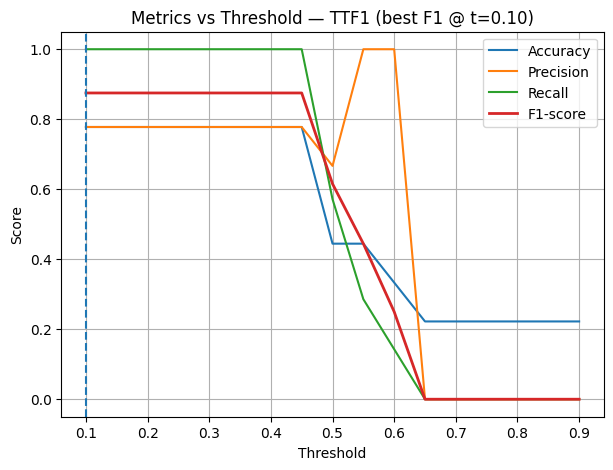

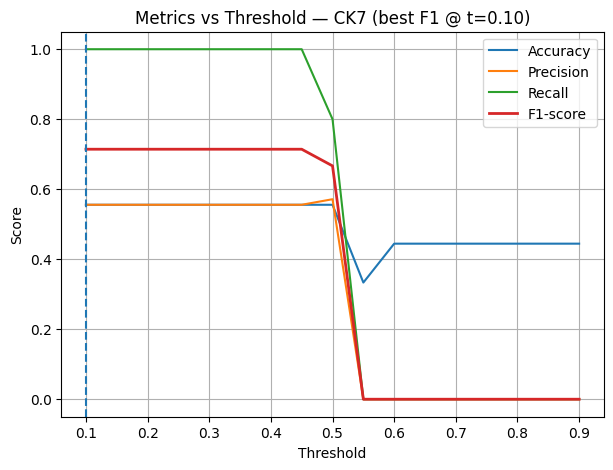

Best thresholds (on TEST quick view): 0.1 0.1


In [ ]:
MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/model_TTF1_CK7_CT_radiomics_effnetlike3D.keras"
model = tf.keras.models.load_model(MODEL_PATH)
print("Loaded model from:", MODEL_PATH)

y_true_ttf1, y_true_ck7 = [], []
for _, targets in test_ds.unbatch():
    y_true_ttf1.append(int(np.squeeze(targets["TTF1"].numpy())))
    y_true_ck7.append(int(np.squeeze(targets["CK7"].numpy())))
y_true_ttf1 = np.array(y_true_ttf1, dtype=int)
y_true_ck7  = np.array(y_true_ck7,  dtype=int)

pred = model.predict(test_ds, verbose=0)
p_test_ttf1 = pred["TTF1"].ravel()
p_test_ck7  = pred["CK7"].ravel()

def plot_threshold_metrics(y_true, y_prob, name):
    thresholds = np.arange(0.10, 0.91, 0.05)
    acc, prec, rec, f1 = [], [], [], []

    for t in thresholds:
        y_pred = (y_prob >= t).astype(int)
        acc.append(accuracy_score(y_true, y_pred))
        prec.append(precision_score(y_true, y_pred, zero_division=0))
        rec.append(recall_score(y_true, y_pred, zero_division=0))
        f1.append(f1_score(y_true, y_pred, zero_division=0))

    best_idx = int(np.argmax(f1))
    best_t = float(thresholds[best_idx])

    plt.figure(figsize=(7,5))
    plt.plot(thresholds, acc,  label="Accuracy")
    plt.plot(thresholds, prec, label="Precision")
    plt.plot(thresholds, rec,  label="Recall")
    plt.plot(thresholds, f1,   label="F1-score", linewidth=2)
    plt.axvline(best_t, linestyle="--")
    plt.xlabel("Threshold")
    plt.ylabel("Score")
    plt.title(f"Metrics vs Threshold — {name} (best F1 @ t={best_t:.2f})")
    plt.legend()
    plt.grid(True)
    plt.show()

    return best_t

best_t_ttf1 = plot_threshold_metrics(y_true_ttf1, p_test_ttf1, "TTF1")
best_t_ck7  = plot_threshold_metrics(y_true_ck7,  p_test_ck7,  "CK7")

print("Best thresholds (on TEST quick view):", best_t_ttf1, best_t_ck7)



TTF1 — binary metrics
Threshold: 0.47
Accuracy:  0.6667
Precision: 0.7500
Recall:    0.8571
F1-score:  0.8000
Confusion matrix [[TN FP] [FN TP]]:
[[0 2]
 [1 6]]


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


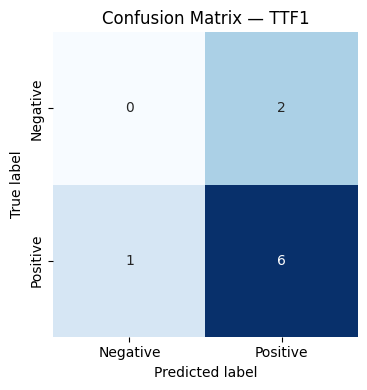


CK7 — binary metrics
Threshold: 0.48
Accuracy:  0.6667
Precision: 0.6250
Recall:    1.0000
F1-score:  0.7692
Confusion matrix [[TN FP] [FN TP]]:
[[1 3]
 [0 5]]


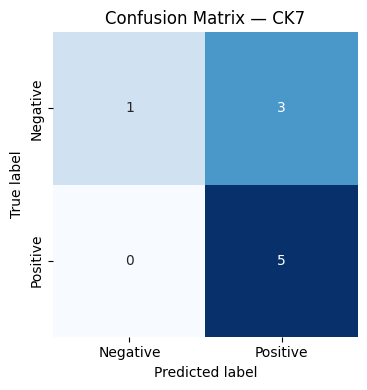

In [ ]:
TTF1_THR = float(best_t_ttf1) if "best_t_ttf1" in globals() else 0.50
CK7_THR  = float(best_t_ck7)  if "best_t_ck7"  in globals() else 0.50

TTF1_THR = 0.47 # 0.47
CK7_THR = 0.48  # 0.48

pred = model.predict(test_ds, verbose=0)
y_pred_ttf1 = (pred["TTF1"].ravel() >= TTF1_THR).astype(int)
y_pred_ck7  = (pred["CK7"].ravel()  >= CK7_THR).astype(int)

def plot_confusion_matrix(y_true, y_pred, name):
    cm = confusion_matrix(y_true, y_pred)
    labels = ["Negative", "Positive"]

    plt.figure(figsize=(4.5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels, square=True)
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

def print_binary_metrics(y_true, y_pred, name, thr):
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec  = recall_score(y_true, y_pred, zero_division=0)
    f1   = f1_score(y_true, y_pred, zero_division=0)
    cm   = confusion_matrix(y_true, y_pred)

    print(f"\n{name} — binary metrics")
    print(f"Threshold: {thr:.2f}")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print("Confusion matrix [[TN FP] [FN TP]]:")
    print(cm)

    plot_confusion_matrix(y_true, y_pred, name)

print_binary_metrics(y_true_ttf1, y_pred_ttf1, "TTF1", TTF1_THR)
print_binary_metrics(y_true_ck7,  y_pred_ck7,  "CK7",  CK7_THR)


In [ ]:
import numpy as np

MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/model_TTF1_CK7_CT_radiomics_effnetlike3D_v2.keras"
EPOCHS = 25

radio_dim = X_radio.shape[1]

model = build_effnetlike3d_multimodal_twoheads(
    radio_dim=radio_dim,
    input_shape_3d=TARGET_SHAPE + (1,),
    lr=3e-5,
    l2_reg=1e-4,
    drop_img=0.45,
    drop_radio=0.25,
    drop_fusion=0.35,
    use_focal=False
)


model.summary()

callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_loss", save_best_only=True),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

print("Best model saved to:", MODEL_PATH)


Model: "EffNetLike3D_MBConv_SE_Multimodal"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ct (InputLayer)     │ (None, 128, 128,  │          0 │ -                 │
│                     │ 128, 1)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv3D)  │ (None, 64, 64,    │        432 │ ct[0][0]          │
│                     │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 64, 64,    │         64 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_swish          │ (None, 64, 64,    │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_expand_conv      │ (None, 64, 64,    │        512 │ stem_swish[0][0]  │
│ (Conv3D)            │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_expand_bn        │ (None, 64, 64,    │        128 │ b1_expand_conv[0… │
│ (BatchNormalizatio… │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_expand_swish     │ (None, 64, 64,    │          0 │ b1_expand_bn[0][… │
│ (Activation)        │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_conv3d_conv      │ (None, 64, 64,    │     27,648 │ b1_expand_swish[… │
│ (Conv3D)            │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_conv3d_bn        │ (None, 64, 64,    │        128 │ b1_conv3d_conv[0… │
│ (BatchNormalizatio… │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_conv3d_swish     │ (None, 64, 64,    │          0 │ b1_conv3d_bn[0][… │
│ (Activation)        │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_se_gap           │ (None, 32)        │          0 │ b1_conv3d_swish[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_se_fc1 (Dense)   │ (None, 8)         │        264 │ b1_se_gap[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_se_fc2 (Dense)   │ (None, 32)        │        288 │ b1_se_fc1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_se_reshape       │ (None, 1, 1, 1,   │          0 │ b1_se_fc2[0][0]   │
│ (Reshape)           │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_se_scale         │ (None, 64, 64,    │          0 │ b1_conv3d_swish[… │
│ (Multiply)          │ 64, 32)           │            │ b1_se_reshape[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_project_conv     │ (None, 64, 64,    │        512 │ b1_se_scale[0][0] │
│ (Conv3D)            │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_project_bn       │ (None, 64, 64,    │         64 │ b1_project_conv[… │
│ (BatchNormalizatio… │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 995,326 (3.80 MB)

 Trainable params: 993,534 (3.79 MB)

 Non-trainable params: 1,792 (7.00 KB)

Epoch 1/25
     33/Unknown 81s 597ms/step - CK7_AUC: 0.5591 - CK7_BinAcc: 0.5408 - CK7_loss: 0.6987 - TTF1_AUC: 0.5681 - TTF1_BinAcc: 0.6020 - TTF1_loss: 0.6750 - loss: 1.6082

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


33/33 ━━━━━━━━━━━━━━━━━━━━ 94s 1s/step - CK7_AUC: 0.5564 - CK7_BinAcc: 0.5399 - CK7_loss: 0.6995 - TTF1_AUC: 0.5658 - TTF1_BinAcc: 0.6006 - TTF1_loss: 0.6754 - loss: 1.6092 - val_CK7_AUC: 0.6905 - val_CK7_BinAcc: 0.6154 - val_CK7_loss: 0.6745 - val_TTF1_AUC: 0.4583 - val_TTF1_BinAcc: 0.6154 - val_TTF1_loss: 0.6837 - val_loss: 1.5934 - learning_rate: 3.0000e-05
Epoch 2/25
33/33 ━━━━━━━━━━━━━━━━━━━━ 33s 320ms/step - CK7_AUC: 0.4239 - CK7_BinAcc: 0.4983 - CK7_loss: 0.7241 - TTF1_AUC: 0.3792 - TTF1_BinAcc: 0.4279 - TTF1_loss: 0.7156 - loss: 1.6739 - val_CK7_AUC: 0.7262 - val_CK7_BinAcc: 0.5385 - val_CK7_loss: 0.6745 - val_TTF1_AUC: 0.4167 - val_TTF1_BinAcc: 0.6923 - val_TTF1_loss: 0.6731 - val_loss: 1.5842 - learning_rate: 3.0000e-05
Epoch 3/25
33/33 ━━━━━━━━━━━━━━━━━━━━ 31s 298ms/step - CK7_AUC: 0.4705 - CK7_BinAcc: 0.4878 - CK7_loss: 0.7025 - TTF1_AUC: 0.4966 - TTF1_BinAcc: 0.5583 - TTF1_loss: 0.6843 - loss: 1.6208 - val_CK7_AUC: 0.7619 - val_CK7_BinAcc: 0.6154 - val_CK7_loss: 0.6766 - v

Loaded model from: /content/drive/MyDrive/Colab Notebooks/model_TTF1_CK7_CT_radiomics_effnetlike3D_v2.keras


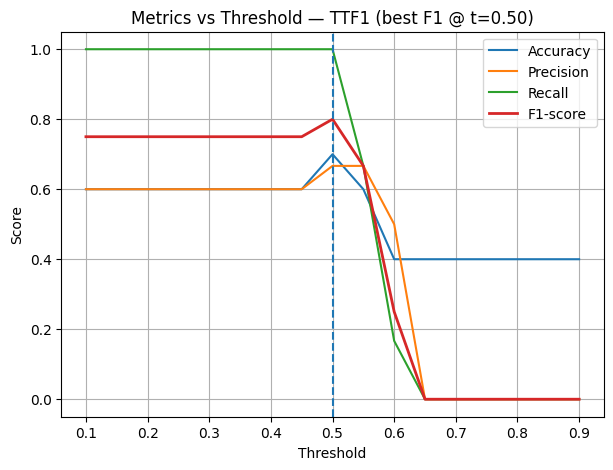

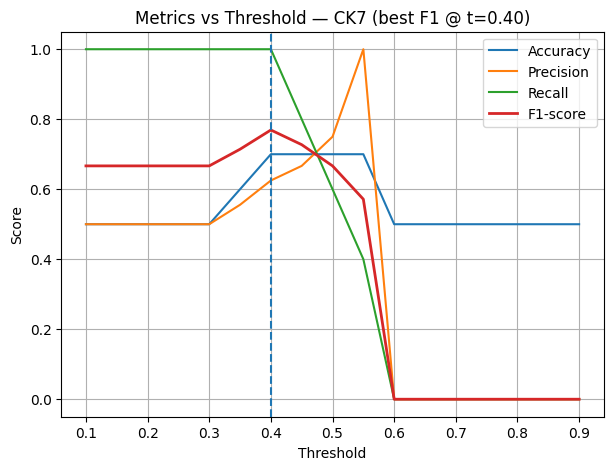

Best thresholds (on TEST quick view): 0.5000000000000001 0.40000000000000013


In [ ]:
MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/model_TTF1_CK7_CT_radiomics_effnetlike3D_v2.keras"
model = tf.keras.models.load_model(MODEL_PATH)
print("Loaded model from:", MODEL_PATH)

y_true_ttf1, y_true_ck7 = [], []
for _, targets in test_ds.unbatch():
    y_true_ttf1.append(int(np.squeeze(targets["TTF1"].numpy())))
    y_true_ck7.append(int(np.squeeze(targets["CK7"].numpy())))
y_true_ttf1 = np.array(y_true_ttf1, dtype=int)
y_true_ck7  = np.array(y_true_ck7,  dtype=int)

pred = model.predict(test_ds, verbose=0)
p_test_ttf1 = pred["TTF1"].ravel()
p_test_ck7  = pred["CK7"].ravel()

def plot_threshold_metrics(y_true, y_prob, name):
    thresholds = np.arange(0.10, 0.91, 0.05)
    acc, prec, rec, f1 = [], [], [], []

    for t in thresholds:
        y_pred = (y_prob >= t).astype(int)
        acc.append(accuracy_score(y_true, y_pred))
        prec.append(precision_score(y_true, y_pred, zero_division=0))
        rec.append(recall_score(y_true, y_pred, zero_division=0))
        f1.append(f1_score(y_true, y_pred, zero_division=0))

    best_idx = int(np.argmax(f1))
    best_t = float(thresholds[best_idx])

    plt.figure(figsize=(7,5))
    plt.plot(thresholds, acc,  label="Accuracy")
    plt.plot(thresholds, prec, label="Precision")
    plt.plot(thresholds, rec,  label="Recall")
    plt.plot(thresholds, f1,   label="F1-score", linewidth=2)
    plt.axvline(best_t, linestyle="--")
    plt.xlabel("Threshold")
    plt.ylabel("Score")
    plt.title(f"Metrics vs Threshold — {name} (best F1 @ t={best_t:.2f})")
    plt.legend()
    plt.grid(True)
    plt.show()

    return best_t

best_t_ttf1 = plot_threshold_metrics(y_true_ttf1, p_test_ttf1, "TTF1")
best_t_ck7  = plot_threshold_metrics(y_true_ck7,  p_test_ck7,  "CK7")

print("Best thresholds (on TEST quick view):", best_t_ttf1, best_t_ck7)



TTF1 — binary metrics
Threshold: 0.55
Accuracy:  0.4000
Precision: 0.5000
Recall:    0.6667
F1-score:  0.5714
Confusion matrix [[TN FP] [FN TP]]:
[[0 4]
 [2 4]]


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


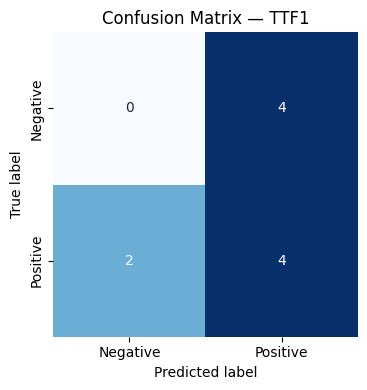


CK7 — binary metrics
Threshold: 0.48
Accuracy:  0.5000
Precision: 0.5000
Recall:    1.0000
F1-score:  0.6667
Confusion matrix [[TN FP] [FN TP]]:
[[0 5]
 [0 5]]


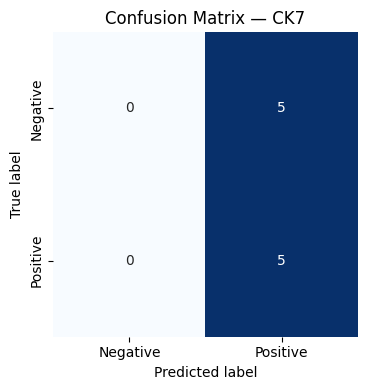

In [ ]:
TTF1_THR = float(best_t_ttf1) if "best_t_ttf1" in globals() else 0.50
CK7_THR  = float(best_t_ck7)  if "best_t_ck7"  in globals() else 0.50

TTF1_THR = 0.55 # 0.45
CK7_THR = 0.48  # 0.48

pred = model.predict(test_ds, verbose=0)
y_pred_ttf1 = (pred["TTF1"].ravel() >= TTF1_THR).astype(int)
y_pred_ck7  = (pred["CK7"].ravel()  >= CK7_THR).astype(int)

def plot_confusion_matrix(y_true, y_pred, name):
    cm = confusion_matrix(y_true, y_pred)
    labels = ["Negative", "Positive"]

    plt.figure(figsize=(4.5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels, square=True)
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

def print_binary_metrics(y_true, y_pred, name, thr):
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec  = recall_score(y_true, y_pred, zero_division=0)
    f1   = f1_score(y_true, y_pred, zero_division=0)
    cm   = confusion_matrix(y_true, y_pred)

    print(f"\n{name} — binary metrics")
    print(f"Threshold: {thr:.2f}")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print("Confusion matrix [[TN FP] [FN TP]]:")
    print(cm)

    plot_confusion_matrix(y_true, y_pred, name)

print_binary_metrics(y_true_ttf1, y_pred_ttf1, "TTF1", TTF1_THR)
print_binary_metrics(y_true_ck7,  y_pred_ck7,  "CK7",  CK7_THR)


In [ ]:
train_ds, val_ds, test_ds = prepare_stratified_datasets(
    data_index,
    ct_paths,
    X_radio,
    y,
    val_split=0.09,
    test_split=0.11
)


--- TOTAL PACIENTI DISPONIBILI: 87 ---
stratify_key
0.0_0.0    14
0.0_1.0    12
1.0_0.0    31
1.0_1.0    30
Name: count, dtype: int64
----------------------------------------

=== RAPORT DISTRIBUTIE DUPA SPLIT ===

Set: TRAIN (Total: 69)
  -> TTF1: 0.0 | CK7: 0.0 : 11 pacienti
  -> TTF1: 0.0 | CK7: 1.0 : 9 pacienti
  -> TTF1: 1.0 | CK7: 0.0 : 25 pacienti
  -> TTF1: 1.0 | CK7: 1.0 : 24 pacienti

Set: VALIDATION (Total: 8)
  -> TTF1: 0.0 | CK7: 0.0 : 1 pacienti
  -> TTF1: 0.0 | CK7: 1.0 : 1 pacienti
  -> TTF1: 1.0 | CK7: 0.0 : 3 pacienti
  -> TTF1: 1.0 | CK7: 1.0 : 3 pacienti

Set: TEST (Total: 10)
  -> TTF1: 0.0 | CK7: 0.0 : 2 pacienti
  -> TTF1: 0.0 | CK7: 1.0 : 2 pacienti
  -> TTF1: 1.0 | CK7: 0.0 : 3 pacienti
  -> TTF1: 1.0 | CK7: 1.0 : 3 pacienti




In [ ]:
import numpy as np

MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/model_TTF1_CK7_CT_radiomics_effnetlike3D_v3.keras"
EPOCHS = 25

radio_dim = X_radio.shape[1]

model = build_effnetlike3d_multimodal_twoheads(
    radio_dim=radio_dim,
    input_shape_3d=TARGET_SHAPE + (1,),
    lr=3e-5,
    l2_reg=1e-4,
    drop_img=0.45,
    drop_radio=0.25,
    drop_fusion=0.35,
    use_focal=False
)


model.summary()

callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_loss", save_best_only=True),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

print("Best model saved to:", MODEL_PATH)


Model: "EffNetLike3D_MBConv_SE_Multimodal"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ct (InputLayer)     │ (None, 128, 128,  │          0 │ -                 │
│                     │ 128, 1)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv3D)  │ (None, 64, 64,    │        432 │ ct[0][0]          │
│                     │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 64, 64,    │         64 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_swish          │ (None, 64, 64,    │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_expand_conv      │ (None, 64, 64,    │        512 │ stem_swish[0][0]  │
│ (Conv3D)            │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_expand_bn        │ (None, 64, 64,    │        128 │ b1_expand_conv[0… │
│ (BatchNormalizatio… │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_expand_swish     │ (None, 64, 64,    │          0 │ b1_expand_bn[0][… │
│ (Activation)        │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_conv3d_conv      │ (None, 64, 64,    │     27,648 │ b1_expand_swish[… │
│ (Conv3D)            │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_conv3d_bn        │ (None, 64, 64,    │        128 │ b1_conv3d_conv[0… │
│ (BatchNormalizatio… │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_conv3d_swish     │ (None, 64, 64,    │          0 │ b1_conv3d_bn[0][… │
│ (Activation)        │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_se_gap           │ (None, 32)        │          0 │ b1_conv3d_swish[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_se_fc1 (Dense)   │ (None, 8)         │        264 │ b1_se_gap[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_se_fc2 (Dense)   │ (None, 32)        │        288 │ b1_se_fc1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_se_reshape       │ (None, 1, 1, 1,   │          0 │ b1_se_fc2[0][0]   │
│ (Reshape)           │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_se_scale         │ (None, 64, 64,    │          0 │ b1_conv3d_swish[… │
│ (Multiply)          │ 64, 32)           │            │ b1_se_reshape[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_project_conv     │ (None, 64, 64,    │        512 │ b1_se_scale[0][0] │
│ (Conv3D)            │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ b1_project_bn       │ (None, 64, 64,    │         64 │ b1_project_conv[… │
│ (BatchNormalizatio… │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 995,326 (3.80 MB)

 Trainable params: 993,534 (3.79 MB)

 Non-trainable params: 1,792 (7.00 KB)

Epoch 1/25
     35/Unknown 137s 1s/step - CK7_AUC: 0.3906 - CK7_BinAcc: 0.3633 - CK7_loss: 0.7328 - TTF1_AUC: 0.2492 - TTF1_BinAcc: 0.3764 - TTF1_loss: 0.7331 - loss: 1.7015   

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


35/35 ━━━━━━━━━━━━━━━━━━━━ 147s 1s/step - CK7_AUC: 0.3914 - CK7_BinAcc: 0.3645 - CK7_loss: 0.7328 - TTF1_AUC: 0.2519 - TTF1_BinAcc: 0.3768 - TTF1_loss: 0.7330 - loss: 1.7013 - val_CK7_AUC: 0.5000 - val_CK7_BinAcc: 0.5000 - val_CK7_loss: 0.7090 - val_TTF1_AUC: 0.1667 - val_TTF1_BinAcc: 0.2500 - val_TTF1_loss: 0.7202 - val_loss: 1.6645 - learning_rate: 3.0000e-05
Epoch 2/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 31s 240ms/step - CK7_AUC: 0.5112 - CK7_BinAcc: 0.4686 - CK7_loss: 0.7167 - TTF1_AUC: 0.2163 - TTF1_BinAcc: 0.5423 - TTF1_loss: 0.7050 - loss: 1.6570 - val_CK7_AUC: 0.5312 - val_CK7_BinAcc: 0.5000 - val_CK7_loss: 0.7092 - val_TTF1_AUC: 0.1667 - val_TTF1_BinAcc: 0.3750 - val_TTF1_loss: 0.7114 - val_loss: 1.6554 - learning_rate: 3.0000e-05
Epoch 3/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 37s 250ms/step - CK7_AUC: 0.5207 - CK7_BinAcc: 0.5659 - CK7_loss: 0.6889 - TTF1_AUC: 0.4708 - TTF1_BinAcc: 0.6150 - TTF1_loss: 0.6908 - loss: 1.6146 - val_CK7_AUC: 0.5312 - val_CK7_BinAcc: 0.5000 - val_CK7_loss: 0.7104 - 

Loaded model from: /content/drive/MyDrive/Colab Notebooks/model_TTF1_CK7_CT_radiomics_effnetlike3D_v3.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


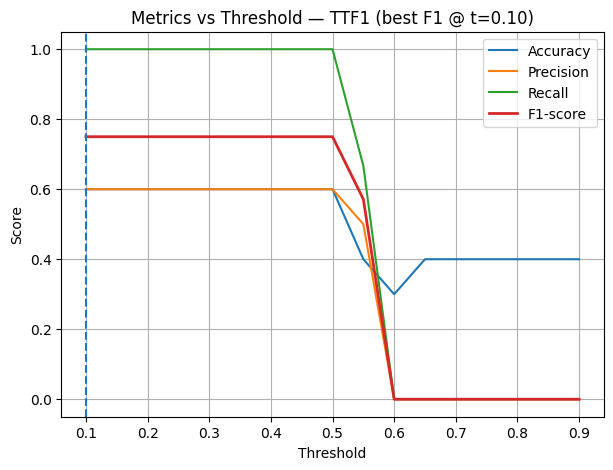

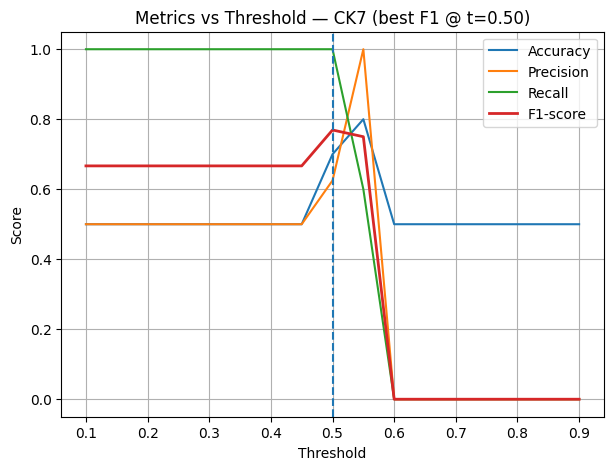

Best thresholds (on TEST quick view): 0.1 0.5000000000000001


In [ ]:
MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/model_TTF1_CK7_CT_radiomics_effnetlike3D_v3.keras"
model = tf.keras.models.load_model(MODEL_PATH)
print("Loaded model from:", MODEL_PATH)

y_true_ttf1, y_true_ck7 = [], []
for _, targets in test_ds.unbatch():
    y_true_ttf1.append(int(np.squeeze(targets["TTF1"].numpy())))
    y_true_ck7.append(int(np.squeeze(targets["CK7"].numpy())))
y_true_ttf1 = np.array(y_true_ttf1, dtype=int)
y_true_ck7  = np.array(y_true_ck7,  dtype=int)

pred = model.predict(test_ds, verbose=0)
p_test_ttf1 = pred["TTF1"].ravel()
p_test_ck7  = pred["CK7"].ravel()


best_t_ttf1 = plot_threshold_metrics(y_true_ttf1, p_test_ttf1, "TTF1")
best_t_ck7  = plot_threshold_metrics(y_true_ck7,  p_test_ck7,  "CK7")

print("Best thresholds (on TEST quick view):", best_t_ttf1, best_t_ck7)


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



TTF1 — binary metrics
Threshold: 0.53
Accuracy:  0.5000
Precision: 0.5556
Recall:    0.8333
F1-score:  0.6667
Confusion matrix [[TN FP] [FN TP]]:
[[0 4]
 [1 5]]


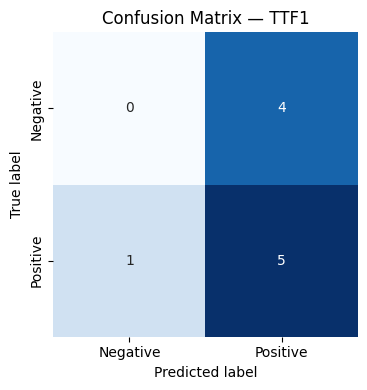


CK7 — binary metrics
Threshold: 0.50
Accuracy:  0.7000
Precision: 0.6250
Recall:    1.0000
F1-score:  0.7692
Confusion matrix [[TN FP] [FN TP]]:
[[2 3]
 [0 5]]


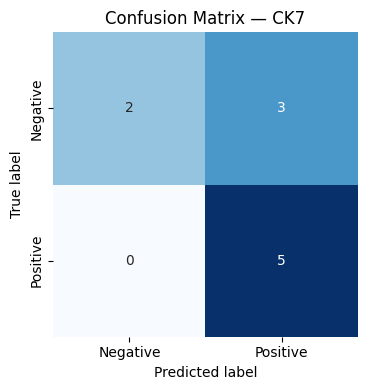

In [ ]:
TTF1_THR = float(best_t_ttf1) if "best_t_ttf1" in globals() else 0.50
CK7_THR  = float(best_t_ck7)  if "best_t_ck7"  in globals() else 0.50

TTF1_THR = 0.53 # 0.53
CK7_THR = 0.5  # 0.5

pred = model.predict(test_ds, verbose=0)
y_pred_ttf1 = (pred["TTF1"].ravel() >= TTF1_THR).astype(int)
y_pred_ck7  = (pred["CK7"].ravel()  >= CK7_THR).astype(int)

print_binary_metrics(y_true_ttf1, y_pred_ttf1, "TTF1", TTF1_THR)
print_binary_metrics(y_true_ck7,  y_pred_ck7,  "CK7",  CK7_THR)


In [ ]:
# model_TTF1_CK7_CT_radiomics_effnetlike3D
# model_TTF1_CK7_CT_radiomics_effnetlike3D_v3